# Week 5 - Part D2: the parallel coordinates plot

Same file, the five numeric columns. Three decisions, each fixed **before** drawing and each written on the figure:

1. **Scaling:** `gdp_pc` goes through log10, then every axis is min-max scaled to 0-1. Plain min-max lets Aldonia flatten GDP (case 3: 58 of 60 below 0.10). Rank would fix that but throws away the size of the gaps. z-score still lets Aldonia set the range (z = +7.5). Log then min-max keeps the gaps and removes the single-value squash.
2. **Axis order:** the greedy chain by |r| from slide 24 (`geolib.corr_chain`'s rule), run on the columns **as they'll be drawn**, so on log GDP.
3. **Clutter control:** everything grey, one region brushed. The rule for which one was set first: the region with the highest median case rate.

All data is synthetic course data for CDB601220 (Week 5).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    ROOT = Path(__file__).resolve().parents[1]
    IN_NOTEBOOK = False
except NameError:
    ROOT = Path.cwd()
    IN_NOTEBOOK = True
sys.path.insert(0, str(ROOT))


def show():
    """Inline in the notebook; as a script just close the figure (the PNG is already saved)."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import geolib as gl
from vizlib import PALETTE, save_fig, style_defaults

DATA = ROOT / "data"
CHARTS = ROOT / "charts"
SUB = ROOT / "submission"
for p in (CHARTS, SUB):
    p.mkdir(exist_ok=True)
style_defaults()
ORANGE, INK, SOFT = PALETTE["highlight"], PALETTE["ink"], PALETTE["ink_soft"]
NUM = ["gdp_pc", "healthcare_access", "urban_pct", "median_age", "cases_per_100k"]


def corr_chain(df, cols):
    """geolib.corr_chain's greedy rule (slide 24). The toolkit version calls np.fill_diagonal on
    DataFrame.values, which pandas 3 hands back read-only, so it crashes on my install. Same rule here."""
    try:
        return gl.corr_chain(df, cols)
    except ValueError:
        r = df[list(cols)].corr().abs().to_numpy(copy=True)
        np.fill_diagonal(r, 0.0)
        i, j = np.unravel_index(np.argmax(r), r.shape)
        order = [cols[i], cols[j]]
        while len(order) < len(cols):
            rest = [c for c in cols if c not in order]
            order.append(max(rest, key=lambda c: r[cols.index(order[-1]), cols.index(c)]))
        return order


def crossings(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return int((((a[:, None] - a[None, :]) * (b[:, None] - b[None, :])) < 0).sum() // 2)


hi = pd.read_csv(DATA / "health_indicators.csv")

In [2]:
# self-check from the brief, on the raw columns
raw_chain = corr_chain(hi, NUM)
r_ac = hi.healthcare_access.corr(hi.cases_per_100k)
print("greedy chain on raw columns:", " -> ".join(raw_chain), f"| r(access, cases) = {r_ac:+.3f}")
assert raw_chain == ["healthcare_access", "cases_per_100k", "urban_pct", "median_age", "gdp_pc"] and round(r_ac, 3) == -0.799

# the frame actually drawn: log10 GDP, then min-max
drawn = hi.assign(gdp_pc=np.log10(hi.gdp_pc))
ORDER = corr_chain(drawn, NUM)
print("greedy chain on the drawn columns (log10 GDP):", " -> ".join(ORDER))
print(drawn[NUM].corr().round(2).to_string())

# brush rule, fixed before drawing
med = hi.groupby("region")[NUM].median()
BRUSH = med.cases_per_100k.idxmax()
print(f"\nregion with the highest median case rate: {BRUSH}")
print(med.round(1).to_string())

greedy chain on raw columns: healthcare_access -> cases_per_100k -> urban_pct -> median_age -> gdp_pc | r(access, cases) = -0.799
greedy chain on the drawn columns (log10 GDP): gdp_pc -> healthcare_access -> cases_per_100k -> urban_pct -> median_age
                   gdp_pc  healthcare_access  urban_pct  median_age  cases_per_100k
gdp_pc               1.00               0.83       0.77        0.80           -0.71
healthcare_access    0.83               1.00       0.75        0.80           -0.80
urban_pct            0.77               0.75       1.00        0.64           -0.62
median_age           0.80               0.80       0.64        1.00           -0.59
cases_per_100k      -0.71              -0.80      -0.62       -0.59            1.00

region with the highest median case rate: Borealis
          gdp_pc  healthcare_access  urban_pct  median_age  cases_per_100k
region                                                                    
Andara    2292.5               47.4       50

In [3]:
N = gl.scale_frame(drawn, NUM, "minmax")
print("adjacent pairs in the drawn order:")
for a, b in zip(ORDER, ORDER[1:]):
    print(f"  {a:>18s} | {b:<18s} r = {drawn[a].corr(drawn[b]):+.2f}  crossings {crossings(N[a], N[b]):>5,} of 1,770")
print(f"median of the drawn gdp axis: {N.gdp_pc.median():.2f} (plain min-max would give {gl.scale_frame(hi, NUM, 'minmax').gdp_pc.median():.3f})")
b = hi.region == BRUSH
for c in ORDER:
    print(f"  {c:>18s}: {BRUSH} median {hi[b][c].median():>9,.1f}   others {hi[~b][c].median():>9,.1f}   "
          f"{BRUSH} median on the 0-1 axis {N[b][c].median():.2f}")
print(f"{BRUSH} countries in the bottom fifth of the urban axis: {(N[b].urban_pct < 0.2).sum()} of {b.sum()}; "
      f"above the overall median case rate: {(hi[b].cases_per_100k > hi.cases_per_100k.median()).sum()} of {b.sum()}")

adjacent pairs in the drawn order:
              gdp_pc | healthcare_access  r = +0.83  crossings   268 of 1,770
   healthcare_access | cases_per_100k     r = -0.80  crossings 1,435 of 1,770
      cases_per_100k | urban_pct          r = -0.62  crossings 1,248 of 1,770
           urban_pct | median_age         r = +0.64  crossings   499 of 1,770
median of the drawn gdp axis: 0.35 (plain min-max would give 0.017)
              gdp_pc: Borealis median   2,157.0   others   2,366.5   Borealis median on the 0-1 axis 0.33
   healthcare_access: Borealis median      45.4   others      50.0   Borealis median on the 0-1 axis 0.47
      cases_per_100k: Borealis median     119.6   others     100.0   Borealis median on the 0-1 axis 0.71
           urban_pct: Borealis median      31.1   others      49.3   Borealis median on the 0-1 axis 0.25
          median_age: Borealis median      27.0   others      28.5   Borealis median on the 0-1 axis 0.45
Borealis countries in the bottom fifth of the urban axi

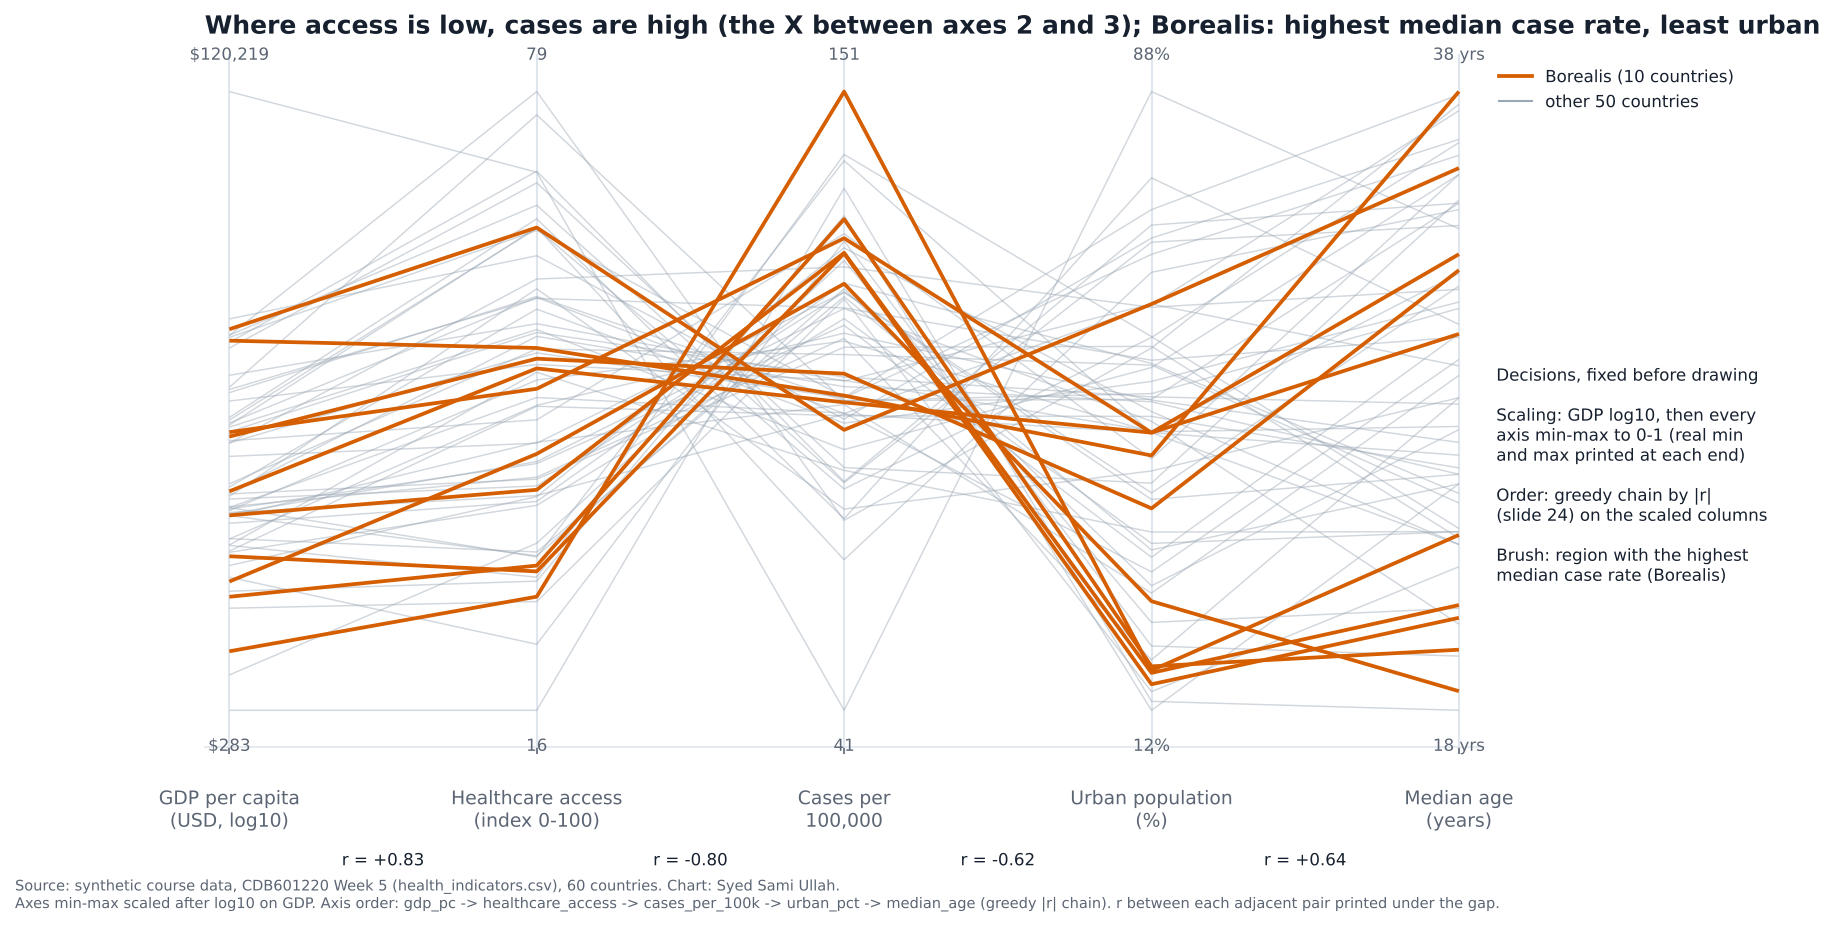

In [4]:
fig, ax = plt.subplots(figsize=(11, 6))
gl.pcp(ax, drawn, ORDER, "minmax", highlight=b.to_numpy(), hl_color=ORANGE, lw_hl=1.8, alpha_bg=0.45)
for t in list(ax.texts):                     # pcp printed log10 ends for GDP; put real units back
    t.remove()
units = {"gdp_pc": "${:,.0f}", "healthcare_access": "{:.0f}", "urban_pct": "{:.0f}%", "median_age": "{:.0f} yrs",
         "cases_per_100k": "{:.0f}"}
for x, c in enumerate(ORDER):
    ax.annotate(units[c].format(hi[c].min()), (x, -0.045), ha="center", va="top", fontsize=8, color=SOFT)
    ax.annotate(units[c].format(hi[c].max()), (x, 1.045), ha="center", va="bottom", fontsize=8, color=SOFT)
names = {"gdp_pc": "GDP per capita\n(USD, log10)", "healthcare_access": "Healthcare access\n(index 0-100)",
         "urban_pct": "Urban population\n(%)", "median_age": "Median age\n(years)", "cases_per_100k": "Cases per\n100,000"}
ax.set_xticklabels([names[c] for c in ORDER], fontsize=9)
ax.tick_params(axis="x", pad=16)
for x, (a_, b_) in enumerate(zip(ORDER, ORDER[1:])):
    ax.text(x + 0.5, -0.17, f"r = {drawn[a_].corr(drawn[b_]):+.2f}", ha="center", fontsize=8, color=INK,
            transform=ax.get_xaxis_transform())
ax.plot([], [], color=ORANGE, lw=1.8, label=f"{BRUSH} (10 countries)")
ax.plot([], [], color=PALETTE["muted"], lw=1, label="other 50 countries")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
ax.text(1.01, 0.55,
        "Decisions, fixed before drawing\n\n"
        "Scaling: GDP log10, then every\naxis min-max to 0-1 (real min\nand max printed at each end)\n\n"
        "Order: greedy chain by |r|\n(slide 24) on the scaled columns\n\n"
        f"Brush: region with the highest\nmedian case rate ({BRUSH})",
        transform=ax.transAxes, fontsize=8, va="top", color=INK)
ax.set_title(f"Where access is low, cases are high (the X between axes 2 and 3); {BRUSH}: highest median case rate, least urban")
save_fig(fig, CHARTS / "partD_pcp.png",
         note="Source: synthetic course data, CDB601220 Week 5 (health_indicators.csv), 60 countries. Chart: Syed Sami Ullah.\n"
              "Axes min-max scaled after log10 on GDP. Axis order: " + " -> ".join(ORDER) + " (greedy |r| chain). r between each adjacent pair printed under the gap.")
save_fig(fig, SUB / "partD_pcp.png")
show()

**What this chart shows.** Between healthcare access and case rate the lines cross in a tight X (1,435 of 1,770 line pairs cross): high access goes with low cases. Between GDP and access, and between urban share and median age, the lines run mostly parallel. Borealis (orange) is not one tidy path: its GDP and access lines spread over most of the range. What it shares is the right-hand side: a median of 119.6 cases per 100,000 against 100.0 for the rest, and the least urban populations (median 31% against 49%), with half of its lines (5 of 10) in the bottom fifth of the urban axis.

**Two relationships I can actually see:**
1. **Access ↔ case rate (axes 2-3):** the X-shaped waist, r = −0.80. Countries with better access have fewer cases per 100,000.
2. **GDP ↔ access (axes 1-2):** mostly parallel lines, r = +0.83 once GDP is on log10. Richer countries have better access. This pair was invisible in case 3's flat min-max GDP axis.

The chain on log GDP is GDP → access → cases → urban → age. It's the raw-data chain from the brief's self-check with GDP moved from the end to the front, because log10 lifts r(GDP, access) from 0.36 to 0.83. Access and cases stay adjacent either way.